# 16 — Cross-dataset results and research synthesis

## Purpose

This notebook brings together the **SOLETE development**, **SOLETE retrospective evaluation**, and **PVOD cross-dataset retrospective evaluation** results. We compare the five nested forecasting representations, summarize the Panchang comparisons and their uncertainty, and examine station-level variation and robustness checks.

The central research comparison is **F3 versus F4**: continuous Sun–Moon astronomy versus the same predictors augmented with the five Panchang categories. We also compare the categorical addition after including continuous sidereal-angle features.

## 1. Research settings and evaluation measures

We evaluate 15-, 30-, and 60-minute PV forecasts using the same fixed LightGBM C1 configuration (300 estimators, learning rate 0.03, 15 leaves).

| Study stage | Forecasting population | Error unit | Summary |
|---|---|---|---|
| SOLETE development | Three chronological folds | kW | Equal-weight mean of the three fold MAEs |
| SOLETE retrospective | June–August 2019 | kW | MAE across the matched evaluation observations |
| PVOD retrospective | Ten independently refitted PV stations | Per-unit nominal capacity | Equal-station mean of station MAEs |

For all paired comparisons, the reported improvement is $\mathrm{MAE}(\mathrm{reference})-\mathrm{MAE}(\mathrm{augmented})$. A positive difference means that the added predictors reduce MAE. Confidence intervals are paired bootstrap percentile intervals computed in the preceding notebooks.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

PROJECT_ROOT = next(
    (
        root for root in (Path.cwd(), *Path.cwd().parents)
        if (root / "results" / "solete_retrospective" / "solete_retrospective_metrics.csv").is_file()
        and (root / "results" / "pvod_feature_comparison" / "pvod_feature_aggregates.csv").is_file()
    ),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Open this notebook within the project after completing SOLETE and PVOD evaluations."
    )
PROJECT_ROOT = PROJECT_ROOT.resolve()
HORIZONS = (15, 30, 60)
SCOPES = ("all", "daylight")
FAMILIES = ("F0", "F1", "F2", "F3", "F4")
SIDEREAL_PAIR = ("F3_sidereal", "F4_sidereal")

print("Cross-dataset result directory:", PROJECT_ROOT / "results")

Cross-dataset result directory: /Users/siddharthgupta/Downloads/NSUT/Semester 1/MTITC102 AI and Machine Learning/Project/results


## 2. Load and verify the completed experiment tables

The development results include fold-level errors and paired prediction intervals. The retrospective tables contain overall and station-specific metrics, matched uncertainty intervals, and skill against persistence. We also use the SOLETE Panchang controls and component-interaction results.

In [2]:
SOURCES = {
    "development_metrics": "feature_comparison/solete_development_fold_metrics.csv",
    "development_intervals": "feature_comparison/solete_feature_comparison_intervals.csv",
    "development_fold_consistency": "feature_comparison/solete_feature_fold_consistency.csv",
    "solete_metrics": "solete_retrospective/solete_retrospective_metrics.csv",
    "solete_intervals": "solete_retrospective/solete_retrospective_intervals.csv",
    "solete_skill": "solete_retrospective/solete_retrospective_selected_model_skill.csv",
    "pvod_aggregates": "pvod_feature_comparison/pvod_feature_aggregates.csv",
    "pvod_station_metrics": "pvod_feature_comparison/pvod_feature_station_metrics.csv",
    "pvod_intervals": "pvod_feature_comparison/pvod_feature_intervals.csv",
    "pvod_skill": "pvod_feature_comparison/pvod_selected_reference_skill.csv",
    "pvod_populations": "pvod_feature_comparison/pvod_feature_populations.csv",
    "control_intervals": "representation_controls/solete_panchang_control_intervals.csv",
    "nonadditivity": "representation_controls/solete_panchang_nonadditivity.csv",
}
T = {}
for name, relative_path in SOURCES.items():
    full_path = PROJECT_ROOT / "results" / relative_path
    if not full_path.is_file():
        raise FileNotFoundError(f"Required experiment table: {full_path}")
    T[name] = pd.read_csv(full_path)

expected_rows = {
    "development_metrics": 162,
    "development_intervals": 30,
    "development_fold_consistency": 90,
    "solete_metrics": 54,
    "solete_intervals": 42,
    "solete_skill": 12,
    "pvod_aggregates": 54,
    "pvod_station_metrics": 540,
    "pvod_intervals": 42,
    "pvod_skill": 6,
    "pvod_populations": 30,
    "control_intervals": 72,
    "nonadditivity": 6,
}
for name, expected in expected_rows.items():
    assert len(T[name]) == expected, f"{name}: expected {expected} rows; found {len(T[name])}"

assert set(T["development_metrics"]["fold"]) == {1, 2, 3}
assert set(T["pvod_station_metrics"]["station"]) == {f"station{i:02d}" for i in range(10)}
assert set(T["pvod_populations"]["horizon_min"]) == set(HORIZONS)
assert T["pvod_populations"].groupby("horizon_min")["test_rows"].sum().to_dict() == {
    15: 53885, 30: 53880, 60: 53870,
}

display(pd.DataFrame([
    {"saved_table": key, "rows": len(value)} for key, value in T.items()
]))
print("Experiment tables: verified")

,saved_table,rows
0,development_metrics,162
1,development_intervals,30
2,development_fold_consistency,90
3,solete_metrics,54
4,solete_intervals,42
5,solete_skill,12
6,pvod_aggregates,54
7,pvod_station_metrics,540
8,pvod_intervals,42
9,pvod_skill,6


Experiment tables: verified


## 3. Feature-family forecasting accuracy

F0 represents measured history; F1 adds Gregorian time; F2 adds solar position; F3 adds continuous Sun–Moon astronomy; and F4 adds the categorical Panchang representation. Each dataset uses its own observational history and scale.

The following tables report the **all-hours** MAE of each feature family. The three SOLETE development folds contribute equally to each development result, while the PVOD table gives each station equal weight.

In [3]:
development_scores = (
    T["development_metrics"]
    .groupby(["horizon_min", "scope", "method"], as_index=False)
    .agg(mae=("mae_kw", "mean"))
)
solete_scores = T["solete_metrics"].rename(columns={"mae_kw": "mae"})
pvod_scores = T["pvod_aggregates"].rename(columns={"macro_mae_pu": "mae"})
SCORES = {
    "SOLETE development": development_scores,
    "SOLETE retrospective": solete_scores,
    "PVOD retrospective": pvod_scores,
}
UNITS = {
    "SOLETE development": "kW",
    "SOLETE retrospective": "kW",
    "PVOD retrospective": "p.u.",
}

accuracy_rows = []
for stage, scores in SCORES.items():
    for horizon in HORIZONS:
        for scope in SCOPES:
            selection = scores.loc[
                scores["horizon_min"].eq(horizon) & scores["scope"].eq(scope)
            ].set_index("method")["mae"]
            assert set(FAMILIES + SIDEREAL_PAIR).issubset(selection.index)
            for family in FAMILIES:
                accuracy_rows.append({
                    "stage": stage, "horizon_min": horizon, "scope": scope,
                    "feature_family": family, "mae": float(selection[family]),
                    "unit": UNITS[stage],
                })
accuracy = pd.DataFrame(accuracy_rows)
assert len(accuracy) == 3 * 3 * 2 * 5

for stage in SCORES:
    subset = accuracy.loc[accuracy["stage"].eq(stage) & accuracy["scope"].eq("all")]
    print(f"{stage} — all-hours MAE ({UNITS[stage]}):")
    display(subset.pivot(index="horizon_min", columns="feature_family", values="mae")
            .loc[list(HORIZONS), list(FAMILIES)].round(5))

SOLETE development — all-hours MAE (kW):


feature_family,F0,F1,F2,F3,F4
horizon_min,,,,,
15,0.18746,0.17734,0.17825,0.18081,0.17919
30,0.24309,0.22188,0.21911,0.22278,0.22190
60,0.32847,0.28648,0.28101,0.28686,0.28545


SOLETE retrospective — all-hours MAE (kW):


feature_family,F0,F1,F2,F3,F4
horizon_min,,,,,
15,0.27834,0.25940,0.26122,0.26157,0.26209
30,0.33867,0.30258,0.30133,0.30187,0.30018
60,0.42792,0.34154,0.34175,0.34262,0.34288


PVOD retrospective — all-hours MAE (p.u.):


feature_family,F0,F1,F2,F3,F4
horizon_min,,,,,
15,0.02334,0.02350,0.02313,0.02408,0.02427
30,0.02996,0.02951,0.02919,0.02986,0.02962
60,0.04005,0.03841,0.03742,0.03836,0.03779


## 4. Paired Panchang effects and their uncertainty

The main comparison is F3 versus F4. The continuous-sidereal comparison is F3 with four sidereal-angle coordinates versus the same continuous inputs plus Panchang categories.

The intervals resample correlated observations in the same way as their source notebooks: days within development folds or SOLETE retrospective samples, and stations plus days for PVOD. Both scopes use the same fitted models but different sets of evaluated observations.

In [4]:
INTERVAL_SPECS = {
    "SOLETE development": {
        "table": "development_intervals", "estimate": "mae_reduction_kw",
        "lower": "ci_lower_kw", "upper": "ci_upper_kw",
        "names": {"F3–F4": "Panchang", "Sidereal control": "Panchang with sidereal control"},
    },
    "SOLETE retrospective": {
        "table": "solete_intervals", "estimate": "mae_reduction_kw",
        "lower": "ci_lower_kw", "upper": "ci_upper_kw",
        "names": {"F3–F4": "Panchang F3 to F4",
                  "Sidereal control": "Panchang with continuous sidereal parents"},
    },
    "PVOD retrospective": {
        "table": "pvod_intervals", "estimate": "macro_mae_reduction_pu",
        "lower": "ci_lower_pu", "upper": "ci_upper_pu",
        "names": {"F3–F4": "Panchang",
                  "Sidereal control": "Panchang with continuous sidereal parents"},
    },
}

def interval_direction(lo, hi):
    return "Added features lower MAE" if lo > 0 else (
        "Reference lower MAE" if hi < 0 else "Unresolved"
    )

comparison_rows = []
for stage, spec in INTERVAL_SPECS.items():
    source = T[spec["table"]]
    for label, comparison_name in spec["names"].items():
        pair = ("F3", "F4") if label == "F3–F4" else SIDEREAL_PAIR
        matched = source.loc[source["comparison"].eq(comparison_name)]
        assert len(matched) == 6, (stage, label, len(matched))
        for row in matched.itertuples(index=False):
            h = int(row.horizon_min)
            scope = row.scope
            point = float(getattr(row, spec["estimate"]))
            lo = float(getattr(row, spec["lower"]))
            hi = float(getattr(row, spec["upper"]))
            sub = SCORES[stage].loc[
                SCORES[stage]["horizon_min"].eq(h) & SCORES[stage]["scope"].eq(scope)
            ].set_index("method")["mae"]
            expected = float(sub[pair[0]] - sub[pair[1]])
            assert np.isclose(point, expected, atol=1e-8, rtol=0), (stage, label, h, scope, point, expected)
            assert lo <= hi and np.isfinite([point, lo, hi]).all()
            comparison_rows.append({
                "stage": stage, "horizon_min": h, "scope": scope,
                "contrast": label, "reference": pair[0], "augmented": pair[1],
                "reduction": point, "ci_lower": lo, "ci_upper": hi,
                "unit": UNITS[stage],
                "relative_reduction_pct": 100 * point / float(sub[pair[0]]),
                "direction": interval_direction(lo, hi),
            })

effects = pd.DataFrame(comparison_rows)
assert len(effects) == 3 * 2 * 3 * 2
primary = effects.loc[effects["contrast"].eq("F3–F4") & effects["scope"].eq("all")]
print("Primary all-hours F3−F4 contrast (positive favors F4):")
display(primary[["stage", "horizon_min", "reduction", "ci_lower", "ci_upper",
                 "unit", "relative_reduction_pct", "direction"]].round(5))

print("Continuous-sidereal parent comparison — all hours:")
sidereal_effect = effects.loc[effects["contrast"].eq("Sidereal control") & effects["scope"].eq("all")]
display(sidereal_effect[["stage", "horizon_min", "reduction", "ci_lower", "ci_upper",
                          "unit", "direction"]].round(5))

Primary all-hours F3−F4 contrast (positive favors F4):


,stage,horizon_min,reduction,ci_lower,ci_upper,unit,relative_reduction_pct,direction
0,SOLETE development,15,0.00162,0.00080,0.00245,kW,0.89713,Added features lower MAE
2,SOLETE development,30,0.00088,-0.00057,0.00232,kW,0.39443,Unresolved
4,SOLETE development,60,0.00142,-0.00089,0.00364,kW,0.49455,Unresolved
12,SOLETE retrospective,15,-0.00052,-0.00139,0.00034,kW,-0.19800,Unresolved
14,SOLETE retrospective,30,0.00168,0.00045,0.00293,kW,0.55776,Added features lower MAE
16,SOLETE retrospective,60,-0.00025,-0.00221,0.00180,kW,-0.07440,Unresolved
24,PVOD retrospective,15,-0.00019,-0.00042,0.00002,p.u.,-0.78617,Unresolved
26,PVOD retrospective,30,0.00024,-0.00011,0.00066,p.u.,0.80354,Unresolved
28,PVOD retrospective,60,0.00056,-0.00016,0.00179,p.u.,1.46177,Unresolved


Continuous-sidereal parent comparison — all hours:


,stage,horizon_min,reduction,ci_lower,ci_upper,unit,direction
6,SOLETE development,15,-0.00001,-0.00121,0.00111,kW,Unresolved
8,SOLETE development,30,0.00074,-0.00082,0.00234,kW,Unresolved
10,SOLETE development,60,-0.00045,-0.00339,0.00247,kW,Unresolved
18,SOLETE retrospective,15,-0.00154,-0.00258,-0.00055,kW,Reference lower MAE
20,SOLETE retrospective,30,0.00029,-0.00126,0.00182,kW,Unresolved
22,SOLETE retrospective,60,0.00245,-0.00048,0.00552,kW,Unresolved
30,PVOD retrospective,15,-0.00025,-0.00087,0.00011,p.u.,Unresolved
32,PVOD retrospective,30,-0.00021,-0.00091,0.00024,p.u.,Unresolved
34,PVOD retrospective,60,0.00070,-0.00020,0.00203,p.u.,Unresolved


## 5. Agreement across horizons, evaluation periods and stations

A category effect is more convincing when it retains a similar direction across development and retrospective periods, persists after including continuous sidereal parents, and appears at multiple PVOD stations.

We report both the **numerical sign** of the F3–F4 difference and whether its interval excludes zero. Numerical agreement alone is weaker than an independently replicated, resolved difference.

In [5]:
primary_all = effects.loc[effects["contrast"].eq("F3–F4") & effects["scope"].eq("all")].copy()
primary_all["point_direction"] = np.where(
    primary_all["reduction"] > 0, "F4", np.where(primary_all["reduction"] < 0, "F3", "Tie")
)
point_agreement = primary_all.pivot(
    index="horizon_min", columns="stage", values="point_direction"
).loc[list(HORIZONS), list(SCORES)]
print("Direction of numerical F3−F4 MAE difference — all hours:")
display(point_agreement)

resolved = effects.loc[effects["contrast"].eq("F3–F4")].groupby(
    ["stage", "scope", "direction"]
).size().unstack(fill_value=0)
print("Number of horizons by interval direction:")
display(resolved)

station_all = T["pvod_station_metrics"].loc[T["pvod_station_metrics"]["scope"].eq("all")]
station_pivot = station_all.pivot(index=["station", "horizon_min"], columns="method", values="mae_pu")
assert station_pivot.shape[0] == 30
station_changes = station_pivot[["F3", "F4", "F3_sidereal", "F4_sidereal"]].copy()
station_changes["F3_minus_F4_pu"] = station_changes["F3"] - station_changes["F4"]
station_changes["sidereal_parent_minus_F4_pu"] = (
    station_changes["F3_sidereal"] - station_changes["F4_sidereal"]
)
station_wins = station_changes.groupby(level="horizon_min").agg(
    f4_station_wins=("F3_minus_F4_pu", lambda x: int((x > 0).sum())),
    f3_station_wins=("F3_minus_F4_pu", lambda x: int((x < 0).sum())),
    mean_f3_minus_f4_pu=("F3_minus_F4_pu", "mean"),
).reset_index()
assert station_wins["f4_station_wins"].tolist() == [2, 6, 4]
print("PVOD station-level F3−F4 outcomes:")
display(station_wins.round(6))

Direction of numerical F3−F4 MAE difference — all hours:


stage,SOLETE development,SOLETE retrospective,PVOD retrospective
horizon_min,,,
15,F4,F3,F3
30,F4,F4,F4
60,F4,F3,F4


Number of horizons by interval direction:


direction                      Added features lower MAE  Unresolved
stage                scope                                         
PVOD retrospective   all                              0           3
                     daylight                         0           3
SOLETE development   all                              1           2
                     daylight                         1           2
SOLETE retrospective all                              1           2
                     daylight                         1           2

PVOD station-level F3−F4 outcomes:


,horizon_min,f4_station_wins,f3_station_wins,mean_f3_minus_f4_pu
0,15,2,8,-0.000189
1,30,6,4,0.000240
2,60,4,6,0.000561


## 6. Previously selected models against persistence

The earlier development-only selection chose F1 for 15-minute forecasts and F2 for 30- and 60-minute forecasts. We report their **retrospective** performance against issue-time persistence on the same target rows.

Relative MAE skill is $100(1-\mathrm{MAE}_{\mathrm{model}}/\mathrm{MAE}_{\mathrm{persistence}})$. It is dimensionless, so it can be compared between SOLETE and PVOD, unlike raw kW and p.u. errors. Skill above zero indicates an improvement over persistence; it does not isolate the incremental effect of a particular astronomical feature family.

In [6]:
solete_skill = T["solete_skill"].loc[T["solete_skill"]["baseline"].eq("issue_persistence")].copy()
solete_skill = solete_skill.rename(columns={
    "development_selected_family": "selected_family",
    "selected_model_mae_kw": "model_mae",
    "baseline_mae_kw": "persistence_mae",
    "mae_skill_pct": "skill_pct",
})
solete_skill["stage"] = "SOLETE retrospective"
solete_skill["unit"] = "kW"

pvod_skill = T["pvod_skill"].rename(columns={
    "model_macro_mae_pu": "model_mae",
    "issue_persistence_macro_mae_pu": "persistence_mae",
    "relative_skill_pct": "skill_pct",
}).copy()
pvod_skill["stage"] = "PVOD retrospective"
pvod_skill["unit"] = "p.u."

skill = pd.concat([solete_skill, pvod_skill], ignore_index=True)
assert len(skill) == 12
assert skill["selected_family"].to_list() == [
    "F1", "F1", "F2", "F2", "F2", "F2",
    "F1", "F1", "F2", "F2", "F2", "F2",
]
np.testing.assert_allclose(
    skill["skill_pct"].to_numpy(dtype=float),
    100 * (1 - skill["model_mae"].to_numpy(dtype=float) /
           skill["persistence_mae"].to_numpy(dtype=float)),
    atol=1e-6, rtol=0,
)
all_skill = skill.loc[skill["scope"].eq("all")]
print("Previously selected models versus issue persistence — all hours:")
display(all_skill[["stage", "horizon_min", "selected_family", "model_mae",
                   "persistence_mae", "unit", "skill_pct"]].round(4))

Previously selected models versus issue persistence — all hours:


,stage,horizon_min,selected_family,model_mae,persistence_mae,unit,skill_pct
0,SOLETE retrospective,15,F1,0.2594,0.2914,kW,10.9700
2,SOLETE retrospective,30,F2,0.3013,0.3804,kW,20.7766
4,SOLETE retrospective,60,F2,0.3418,0.5210,kW,34.4014
6,PVOD retrospective,15,F1,0.0235,0.0265,p.u.,11.4546
8,PVOD retrospective,30,F2,0.0292,0.0398,p.u.,26.6081
10,PVOD retrospective,60,F2,0.0374,0.0645,p.u.,41.9494


## 7. Panchang alignment and component-interaction checks

Notebook 10 compared the aligned F4 block with shifted, jointly permuted, differently coded and individual-component representations on the SOLETE development folds. These controls examine whether model accuracy changes when the categorical information is represented differently.

We also compare the combined F4 improvement with the sum of five individual component improvements. Their difference describes **nonadditivity** under this model.

In [7]:
controls = T["control_intervals"].copy()
null_controls = {
    "shift_17d", "shift_37d", "shift_61d",
    "permutation_1301", "permutation_1302", "permutation_1303",
}
nulls = controls.loc[controls["control"].isin(null_controls)].copy()
assert len(nulls) == 3 * 2 * len(null_controls)
control_summary = nulls.groupby(["horizon_min", "scope"]).agg(
    controls_checked=("control", "nunique"),
    aligned_favored=("classification", lambda x: int((x == "Aligned F4 lower MAE").sum())),
    alternatives_favored=("classification", lambda x: int((x == "Control lower MAE").sum())),
    unresolved=("classification", lambda x: int((x == "Unresolved").sum())),
).reset_index()
assert (control_summary["controls_checked"] == 6).all()
assert (control_summary[["aligned_favored", "alternatives_favored", "unresolved"]].sum(axis=1) == 6).all()
print("SOLETE development alignment controls:")
display(control_summary)

nonadd = T["nonadditivity"][[
    "horizon_min", "scope", "combined_F4_gain_kw",
    "sum_single_component_gains_kw", "nonadditivity_gap_kw",
]].copy()
np.testing.assert_allclose(
    nonadd["combined_F4_gain_kw"] - nonadd["sum_single_component_gains_kw"],
    nonadd["nonadditivity_gap_kw"], atol=1e-9, rtol=0,
)
print("SOLETE Panchang component nonadditivity (kW):")
display(nonadd.round(6))

SOLETE development alignment controls:


,horizon_min,scope,controls_checked,aligned_favored,alternatives_favored,unresolved
0,15,all,6,6,0,0
1,15,daylight,6,6,0,0
2,30,all,6,0,1,5
3,30,daylight,6,0,0,6
4,60,all,6,0,0,6
5,60,daylight,6,1,0,5


SOLETE Panchang component nonadditivity (kW):


,horizon_min,scope,combined_F4_gain_kw,sum_single_component_gains_kw,nonadditivity_gap_kw
0,15,all,0.001622,0.004425,-0.002803
1,15,daylight,0.003223,0.008031,-0.004808
2,30,all,0.000879,0.004672,-0.003793
3,30,daylight,0.001726,0.007918,-0.006193
4,60,all,0.001419,0.007050,-0.005631
5,60,daylight,0.003815,0.005067,-0.001253


## 8. Visual comparison of relative Panchang effects

To put SOLETE and PVOD on a comparable vertical scale, this figure expresses the all-hours F3−F4 MAE difference as a **percentage of F3 MAE**, with its paired interval scaled by the same reference error.

The points show relative error differences within each dataset and evaluation stage. The lines connect horizons for visual comparison; each horizon remains a separate forecasting task.

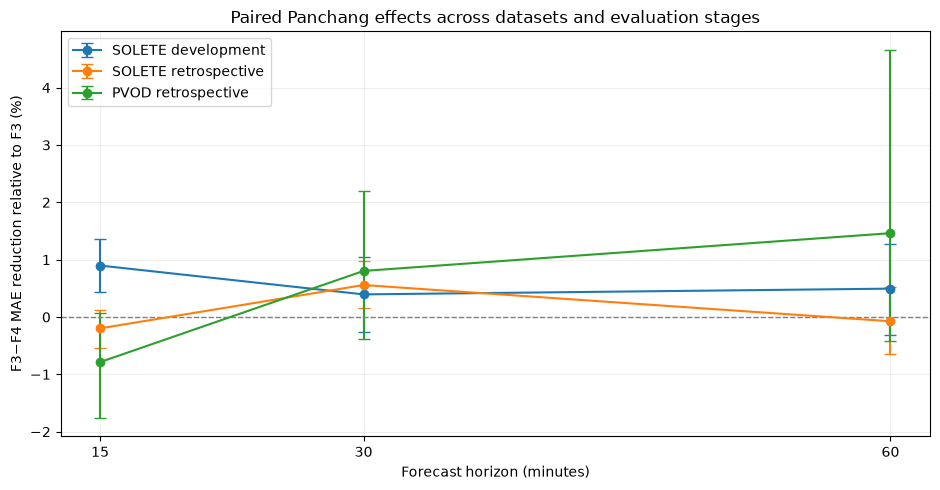

In [8]:
fig, ax = plt.subplots(figsize=(9.5, 5))
for stage in SCORES:
    subset = primary_all.loc[primary_all["stage"].eq(stage)].sort_values("horizon_min")
    base = []
    for row in subset.itertuples(index=False):
        score = SCORES[stage].loc[
            SCORES[stage]["horizon_min"].eq(row.horizon_min)
            & SCORES[stage]["scope"].eq("all")
            & SCORES[stage]["method"].eq("F3"), "mae"
        ]
        assert len(score) == 1
        base.append(float(score.iloc[0]))
    denominator = np.asarray(base)
    x = subset["horizon_min"].to_numpy(dtype=float)
    y = 100 * subset["reduction"].to_numpy(dtype=float) / denominator
    lower = 100 * subset["ci_lower"].to_numpy(dtype=float) / denominator
    upper = 100 * subset["ci_upper"].to_numpy(dtype=float) / denominator
    assert (lower <= y).all() and (y <= upper).all()
    ax.errorbar(x, y, yerr=np.vstack((y - lower, upper - y)),
                marker="o", capsize=4, label=stage)
ax.axhline(0, color="gray", linestyle="--", linewidth=1)
ax.set_xticks(HORIZONS)
ax.set_xlabel("Forecast horizon (minutes)")
ax.set_ylabel("F3−F4 MAE reduction relative to F3 (%)")
ax.set_title("Paired Panchang effects across datasets and evaluation stages")
ax.legend()
ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

## 9. Interpretation and scientific limitations

The results show that **Panchang categories can alter forecasting accuracy, but their added value is sensitive to the forecasting context**. In SOLETE development, the 15-minute F3–F4 difference favors F4. In SOLETE retrospective evaluation, the 30-minute difference favors F4, whereas the other horizons remain unresolved. In the ten-station PVOD evaluation, the paired hierarchical intervals include zero at all three horizons.

These findings support an interpretation of Panchang as a **categorical representation of deterministic astronomical state**. The categories do not introduce a new measured physical driver. The continuous-sidereal and shifted/permuted controls show why better forecasting accuracy alone does not establish a special physical or causal Panchang effect.

**Limits of inference:**

- SOLETE's June–August 2019 evaluation period and PVOD were examined in previous research. These results are labeled retrospective and are not independent blind confirmation.
- The new unified F0–F4 experiments use a fixed LightGBM configuration. Earlier multi-architecture findings belong to the historical research record and require separately qualified synthesis.
- The paired bootstrap intervals quantify sampling variation conditional on the trained forecasts. They do not incorporate repeated model-fitting randomness.
- The many feature, horizon, daylight and representation-control comparisons are exploratory; nominal 95% intervals do not provide familywise multiplicity control.
- SOLETE and PVOD have different observation cadences, geographic conditions and target units. Relative effects and within-dataset comparisons are more interpretable than direct comparisons of raw MAE.
- Station-specific PVOD refitting assesses cross-dataset replication of the experimental specification rather than zero-shot transfer of model weights.

The appropriate conclusion is **architecture- and context-dependent representation sensitivity, with no established universal forecasting advantage for categorical Panchang features**.

## 10. Save the synthesis tables

The consolidated tables record feature-family errors, paired Panchang effects, selected-model skill, station heterogeneity, and SOLETE alignment-control results. They provide the numerical basis for the final research report.

In [9]:
OUTPUT_DIR = PROJECT_ROOT / "results" / "cross_dataset_synthesis"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
OUTPUTS = {
    "feature_accuracy": (accuracy, "feature_family_mae.csv"),
    "panchang_effects": (effects, "panchang_paired_effects.csv"),
    "selected_skill": (skill, "selected_model_persistence_skill.csv"),
    "station_wins": (station_wins, "pvod_station_f3_f4_summary.csv"),
    "control_summary": (control_summary, "solete_alignment_control_summary.csv"),
    "nonadditivity": (nonadd, "solete_component_nonadditivity.csv"),
}
for label, (frame, filename) in OUTPUTS.items():
    path = OUTPUT_DIR / filename
    frame.to_csv(path, index=False, float_format="%.12g")
    reloaded = pd.read_csv(path)
    assert len(reloaded) == len(frame), (label, len(reloaded), len(frame))
    print(path.relative_to(PROJECT_ROOT), "—", len(frame), "rows")

assert len(primary_all) == 9
assert len(station_wins) == 3
assert len(control_summary) == 6
assert len(nonadd) == 6
print("NOTEBOOK 11: CROSS-DATASET SYNTHESIS CHECKS PASSED")

results/cross_dataset_synthesis/feature_family_mae.csv — 90 rows
results/cross_dataset_synthesis/panchang_paired_effects.csv — 36 rows
results/cross_dataset_synthesis/selected_model_persistence_skill.csv — 12 rows
results/cross_dataset_synthesis/pvod_station_f3_f4_summary.csv — 3 rows
results/cross_dataset_synthesis/solete_alignment_control_summary.csv — 6 rows
results/cross_dataset_synthesis/solete_component_nonadditivity.csv — 6 rows
NOTEBOOK 11: CROSS-DATASET SYNTHESIS CHECKS PASSED


## Research conclusion

Across SOLETE and PVOD, adding categorical Panchang features to continuous astronomical predictors produces **small, inconsistent changes** in photovoltaic forecasting error under fixed LightGBM settings. Some SOLETE comparisons show lower MAE with F4, but these results vary across the development and retrospective periods and do not resolve consistently across PVOD stations.

The evidence supports **conditional representation effects**, not a universal Panchang improvement. Calendar and astronomical variables remain valuable candidates for time-series representation studies, and claims about their incremental benefit should be made separately for each dataset, model, horizon and evaluation population.